In [1]:

!pip install  -r "/content/drive/MyDrive/Reinforcement Learning Project/requirements.txt"




     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.5/80.5 MB 13.9 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 887.9/887.9 MB 1.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 594.3/594.3 MB 1.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.2/10.2 MB 141.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 88.0/88.0 MB 9.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 954.8/954.8 kB 52.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 193.1/193.1 MB 6.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 71.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.6/63.6 MB 12.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 267.5/267.5 MB 4.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 288.2/288.2 MB 4.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 322.4/322.4 MB 1.5 MB/s eta 0:00:00
   

In [2]:
%%capture
# Environment
import gym
gym.logger.set_level(40)
from warnings import filterwarnings
filterwarnings(action="ignore")
import pybullet as p
import pybullet_envs

# Models and computation
import torch # will use pyTorch to handle NN
import torch.nn as nn
import torch.nn.functional as F
from torch.distributions import Normal
from torch.distributions import Categorical
import torch.optim as optim
import numpy as np
np.bool8 = np.bool_ # take care of incompatibility between gym==0.25.2 and numpy > 2.0
import random
from random import sample
import math

# Visualization
import matplotlib
import matplotlib.pyplot as plt
%matplotlib inline
from IPython.display import Image
from numpngw import write_apng

# IO
from pathlib import Path
import os

#multiprocessing
import multiprocessing as mp

In [3]:
#calculate the odds of winning if hit, odds of winning if stay
def calculate_initial_odds(dealer_card, card_amounts, usable_ace):
  if usable_ace:
    card_amounts[0] -= 1
    #card_amounts[-1] -= 1
  if dealer_card == 1 or dealer_card == 11:
    card_amounts[0] -= 1
    #card_amounts[-1] -= 1
  elif dealer_card == 10:
    #check card_amounts at positions 11,12,13,14, substract 1 from the highest one
    card_amounts[-1] -= 1
  return card_amounts



In [4]:
def calculate_odds_for_dealer(dealer_card, card_amounts, cur_player_sum):
  #idea here to find the probability of us losing to the dealer if we stay
  total_cards = sum(card_amounts)

  #step 1: calculate all possible combinations of the dealer's 2nd card
  probs = []
  sums = []

  for i in range(0, len(card_amounts)):
    probability = card_amounts[i] / total_cards
    probs.append(probability)
    sums.append(dealer_card + i + 1)

  probs.append(card_amounts[0] / total_cards)
  sums.append(dealer_card + 11)
  #step 2: calculate the probability the sum of each combination is >= cur_player_sum
  weight = 0
  num = 0
  for i in range(0, len(sums)):
    if sums[i] > cur_player_sum:
      weight += probs[i]
      num += 1
  #step 3: calculate the probability
  if num == 0:
    return 0
  probability = weight / num
  #return probability
  return probability


In [5]:
def calculate_odds(dealer_card, cur_player_sum, card_amounts):
  if cur_player_sum == 21:
    v = [1, -1]
    return v
  amount_needed = 21 - cur_player_sum
  #sum of card_amounts to index amount_needed
  if amount_needed >= 10:
    v = [-1, 1]
    return v

  top_val = 0
  bottom_val = 0
  #top_val is sum of index from 0 to amount_needed + 1
  #bottom_val is just sum of card_amounts - card_amounts[0]
  for i in range(0,amount_needed):
    top_val += card_amounts[i]
  for i in range(0, len(card_amounts)):
    bottom_val += card_amounts[i]
  hit = (top_val / bottom_val)
  stay = 1 - hit
  v = [stay, hit]
  return v

In [6]:
def update_card_amounts(cur, old, card_amounts):
  new_card = cur - old
  #print(new_card)
  if new_card == 1 or new_card == 11:
    card_amounts[0] -= 1
    #card_amounts[-1] -= 1
  elif new_card == 10:
        card_amounts[-1] -= 1
  else:
    card_amounts[new_card-1] -= 1
  return card_amounts

In [ ]:
env = gym.make('Blackjack-v1', natural=False, sab=False)
card_amounts = [4,4,4,4,4,4,4,4,4,16]
env.seed(0)
s = env.reset()
print(f"Playser sum: {s[0]}")
print(f"Dealer card: {s[1]}")
print(f"Usable ace: {s[2]}")
card_amounts = calculate_initial_odds(s[1], card_amounts, s[2])
old = s[0]
cur = s[0]
is_terminal = False
while not is_terminal:
  #showcase probs
  probs = calculate_odds(s[1], s[0], card_amounts)
  print(f"Stay: {probs[0]}")
  print(f"Hit: {probs[1]}")
  action = input()
  s, reward, is_terminal, _ = env.step(int(action))
  print(f"Playser sum: {s[0]}")
  print(f"Dealer card: {s[1]}")
  print(f"Usable ace: {s[2]}")
  #update
  card_amounts = update_card_amounts(old, s[0], card_amounts)
  old = s[0]
  print(card_amounts)
print(reward)
env.close()

Playser sum: 11
Dealer card: 10
Usable ace: False
Stay: 0
Hit: 1
1
Playser sum: 12
Dealer card: 10
Usable ace: False
[4, 4, 4, 4, 4, 4, 4, 4, 3, 15]
Stay: 0.30000000000000004
Hit: 0.7
1
Playser sum: 13
Dealer card: 10
Usable ace: False
[4, 4, 4, 4, 4, 4, 4, 4, 2, 15]
Stay: 0.34693877551020413
Hit: 0.6530612244897959
1
Playser sum: 16
Dealer card: 10
Usable ace: False
[4, 4, 4, 4, 4, 4, 3, 4, 2, 15]
Stay: 0.5833333333333333
Hit: 0.4166666666666667
0
Playser sum: 16
Dealer card: 10
Usable ace: False
[4, 4, 4, 4, 4, 4, 3, 4, 2, 14]
-1.0


In [ ]:
env = gym.make('Blackjack-v1', natural=False, sab=False)
images = []
s = env.reset()
img = env.render(mode='rgb_array')
images.append(img)

done = False
steps = 0

while not done:
    action = env.action_space.sample()
    steps += 1
    obs, reward, done, info = env.step(action)
    img = env.render(mode='rgb_array')
    images.append(img)
    if steps > 60:
      break
env.close()

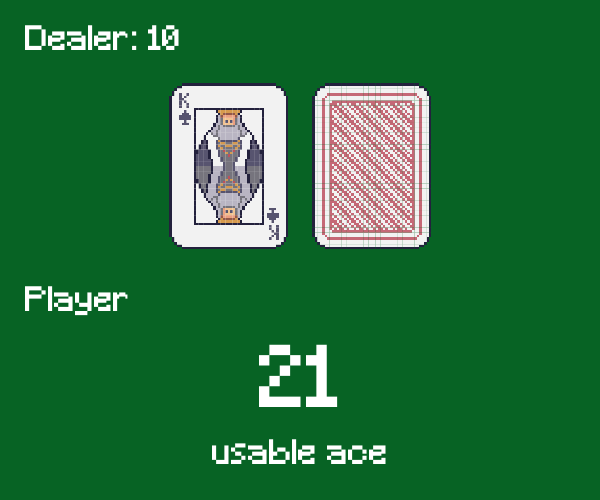

In [ ]:
write_apng('anim.png', images, delay=20)
Image(filename='anim.png')

In [ ]:
print('observation space:', env.observation_space)
print('action space:', env.action_space)

observation space: Tuple(Discrete(32), Discrete(11), Discrete(2))
action space: Discrete(2)


In [7]:
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
class PolicyNetwork(nn.Module):
    def __init__(self, s_size, a_size, fc1_units=32, fc2_units=32, initial_std = 0.1):
        super().__init__()
        self.fc1 = nn.Linear(s_size, fc1_units)
        self.fc2 = nn.Linear(fc1_units, fc2_units)
        self.fc3 = nn.Linear(fc2_units, a_size)


        torch.nn.init.xavier_uniform_(self.fc1.weight)
        torch.nn.init.xavier_uniform_(self.fc2.weight)
        torch.nn.init.xavier_uniform_(self.fc3.weight)
        torch.nn.init.zeros_(self.fc1.bias)
        torch.nn.init.zeros_(self.fc2.bias)
        torch.nn.init.zeros_(self.fc3.bias)

        self.std = nn.Parameter(torch.ones(a_size) * initial_std)


    def forward(self, state):
        x = F.relu(self.fc1(state))
        x = F.relu(self.fc2(x))
        x = self.fc3(x)
        return x

    def select_greedy_action(self, state):
      state = torch.from_numpy(state).float().unsqueeze(0).to(device)
      state = state.to(next(self.parameters()).device)
      x = self.forward(state)
      action_np = torch.argmax(torch.tensor(x)).item()
      return action_np

In [8]:
class EVOAgent(nn.Module):
    def __init__(self, s_size, a_size, initial_std, lr, env):
        super().__init__()
        self.PolicyNetwork = PolicyNetwork(s_size, a_size, 32, 32, initial_std)
        self.lr = lr
        self.env = env
        self.std = initial_std



    def one_hot_state(self, state):
      player_sum, dealer_card, usable_ace = state
      player_vec = np.zeros(32)
      dealer_vec = np.zeros(11)
      ace_vec = np.zeros(2)

      player_vec[player_sum] = 1
      dealer_vec[dealer_card - 1] = 1
      ace_vec[usable_ace] = 1

      return np.concatenate([player_vec, dealer_vec, ace_vec])

    def evaluate(self):
      with torch.no_grad():
        total_reward = 0.0
        num_losses = 0
        player_bust = 0
        dealer_beat_player = 0
        for _ in range(20000):
            state = self.env.reset(seed=np.random.randint(0,1e16))
            done = False
            while not done:
                state = self.one_hot_state(state)
                action = self.PolicyNetwork.select_greedy_action(state)
                state, reward, done, _ = self.env.step(action)
                if(reward > 0 or (state[0] == 21 and state[1] != 21)):
                  total_reward += 1
                elif(reward < 0):
                  num_losses += 1
                  #did the dealer win or did i bust?
                  if(state[0] > 21):
                    player_bust += 1
                  else:
                    dealer_beat_player += 1

        return total_reward/20000 , player_bust/num_losses, dealer_beat_player/num_losses


    def get_params_vector(self):
        params = []
        for p in self.PolicyNetwork.parameters():
            params.append(p.data.view(-1))
        return torch.cat(params)

    def set_params_vector(self, vector):
        pointer = 0
        for p in self.PolicyNetwork.parameters():
            num = p.numel()
            p.data = vector[pointer:pointer+num].view_as(p.data).clone()
            pointer += num

    def sample_noise(self):
        params_vector = self.get_params_vector()
        epsilon = torch.randn_like(params_vector)
        return epsilon


    def rollout(self, params_vector):
        self.set_params_vector(params_vector)
        state = self.env.reset(seed=np.random.randint(0,1e6))
        done = False
        total_reward = 0.0
        card_amounts = [4,4,4,4,4,4,4,4,4,16]
        card_amounts = calculate_initial_odds(state[1], card_amounts, state[2])
        old = state[0]
        while not done:
            probs = calculate_odds(state[1], state[0], card_amounts)
            state = self.one_hot_state(state)
            action = self.PolicyNetwork.select_greedy_action(state)
            #if action taken had the highest prob, add to total reward the probabilty, if not then - the probability
            highest__prob_index = np.argmax(probs)
            #print(highest__prob_index)
            if action == highest__prob_index:
                total_reward += probs[action]
            else:
                total_reward += -1
            state, reward, done, _ = self.env.step(action)
            total_reward += reward
            if(done):
              break
            card_amounts = update_card_amounts(state[0], old, card_amounts)
            old = state[0]
        return total_reward


    def worker(self, base_params, sigma, return_queue):
        epsilon = self.sample_noise()
        perturbed_params = base_params + sigma * epsilon
        reward = self.rollout(perturbed_params)
        # send back reward and noise
        return_queue.put((reward, epsilon))


    def train(self, num_workers=8, epochs=100, sigma=0.1):
        best = 0.392
        avg_rewards = []
        win_rates = []
        bust_rate = []
        dealer_win_rates = []
        for epoch in range(epochs):
          base_params = self.get_params_vector()

          rewards = []
          epsilons = []


          for _ in range(num_workers):
              epsilon = self.sample_noise()
              perturbed_params = base_params + sigma * epsilon
              reward = self.rollout(perturbed_params)
              rewards.append(reward)
              epsilons.append(epsilon)

          # Convert to tensors
          rewards = torch.tensor(rewards, dtype=torch.float32)
          epsilons = torch.stack(epsilons)

          # ES update
          update = (self.lr / (num_workers * sigma)) * torch.sum(rewards.view(-1, 1) * epsilons, dim=0)
          new_params = base_params + update
          self.set_params_vector(new_params)


          #evaluate current policy
          win_rate, player_bust_rate, dealer_win_rate = self.evaluate()
          if(win_rate > best):
            best = win_rate
            #save policy with the name "model_at_win_rate"
            filename = f"model_at_{win_rate:.3f}.pt"
            torch.save(self.PolicyNetwork.state_dict(), filename)
            #download file
            from google.colab import files
            files.download(filename)
            print(f"Model saved! at {filename}")

          print(f"Epoch {epoch} | Avg Reward: {rewards.mean():.3f} | Win Rate: {win_rate:.3f} | Player going bust rate: {player_bust_rate:.3f} | Dealer beat player without player going bust rate: {dealer_win_rate:.3f}")
          avg_rewards.append(rewards.mean())
          win_rates.append(win_rate)
          bust_rate.append(player_bust_rate)
          dealer_win_rates.append(dealer_win_rate)
        return avg_rewards, win_rates, bust_rate, dealer_win_rate





In [ ]:
#train the agent
env = gym.make('Blackjack-v1', natural=False, sab=False)
env.seed(0)
agent = EVOAgent(45, env.action_space.n, 0.1, 0.01, env)
avg_rewards, win_rates, bust_rate, dealer_win_rate = agent.train(num_workers=1000, epochs=100, sigma=0.1)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Model saved! at model_at_0.402.pt
Epoch 0 | Avg Reward: -0.310 | Win Rate: 0.402 | Player going bust rate: 0.030 | Dealer beat player without player going bust rate: 0.970


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Model saved! at model_at_0.409.pt
Epoch 1 | Avg Reward: -0.271 | Win Rate: 0.409 | Player going bust rate: 0.031 | Dealer beat player without player going bust rate: 0.969
Epoch 2 | Avg Reward: -0.390 | Win Rate: 0.401 | Player going bust rate: 0.022 | Dealer beat player without player going bust rate: 0.978
Epoch 3 | Avg Reward: -0.257 | Win Rate: 0.398 | Player going bust rate: 0.029 | Dealer beat player without player going bust rate: 0.971
Epoch 4 | Avg Reward: -0.291 | Win Rate: 0.400 | Player going bust rate: 0.026 | Dealer beat player without player going bust rate: 0.974
Epoch 5 | Avg Reward: -0.270 | Win Rate: 0.405 | Player going bust rate: 0.021 | Dealer beat player without player going bust rate: 0.979
Epoch 6 | Avg Reward: -0.266 | Win Rate: 0.394 | Player going bust rate: 0.016 | Dealer beat player without player going bust rate: 0.984
Epoch 7 | Avg Reward: -0.201 | Win Rate: 0.392 | Player going bust rate: 0.000 | Dealer beat player without player going bust rate: 1.000


... (17 outputs left out)

Model saved! at model_at_0.434.pt
Epoch 88 | Avg Reward: -0.101 | Win Rate: 0.434 | Player going bust rate: 0.068 | Dealer beat player without player going bust rate: 0.932
Epoch 89 | Avg Reward: -0.100 | Win Rate: 0.429 | Player going bust rate: 0.076 | Dealer beat player without player going bust rate: 0.924
Epoch 90 | Avg Reward: -0.080 | Win Rate: 0.430 | Player going bust rate: 0.078 | Dealer beat player without player going bust rate: 0.922
Epoch 91 | Avg Reward: -0.008 | Win Rate: 0.433 | Player going bust rate: 0.105 | Dealer beat player without player going bust rate: 0.895


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Model saved! at model_at_0.438.pt
Epoch 92 | Avg Reward: -0.002 | Win Rate: 0.438 | Player going bust rate: 0.085 | Dealer beat player without player going bust rate: 0.915
Epoch 93 | Avg Reward: -0.018 | Win Rate: 0.437 | Player going bust rate: 0.092 | Dealer beat player without player going bust rate: 0.908
Epoch 94 | Avg Reward: -0.062 | Win Rate: 0.431 | Player going bust rate: 0.092 | Dealer beat player without player going bust rate: 0.908
Epoch 95 | Avg Reward: -0.111 | Win Rate: 0.431 | Player going bust rate: 0.090 | Dealer beat player without player going bust rate: 0.910
Epoch 96 | Avg Reward: -0.048 | Win Rate: 0.432 | Player going bust rate: 0.100 | Dealer beat player without player going bust rate: 0.900
Epoch 97 | Avg Reward: -0.044 | Win Rate: 0.437 | Player going bust rate: 0.108 | Dealer beat player without player going bust rate: 0.892
Epoch 98 | Avg Reward: -0.150 | Win Rate: 0.438 | Player going bust rate: 0.104 | Dealer beat player without player going bust rate:

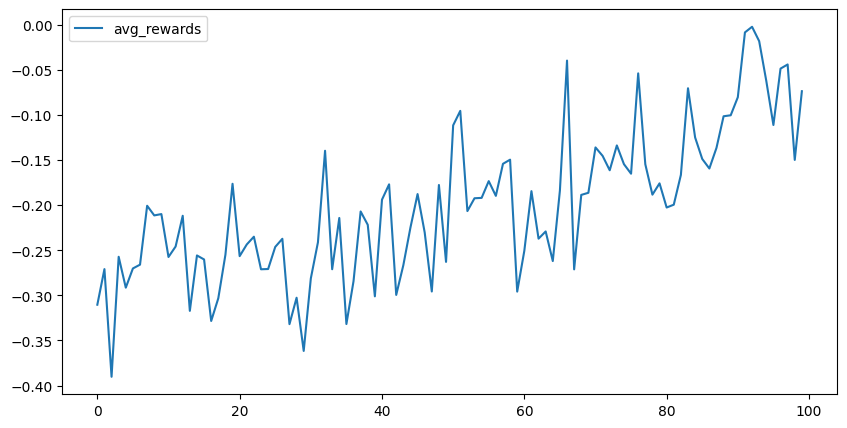

In [ ]:
#plot avg_rewards and win_rates by 1000 epochs
plt.figure(figsize=(10,5))
plt.plot(avg_rewards, label='avg_rewards')
plt.legend()
plt.show()

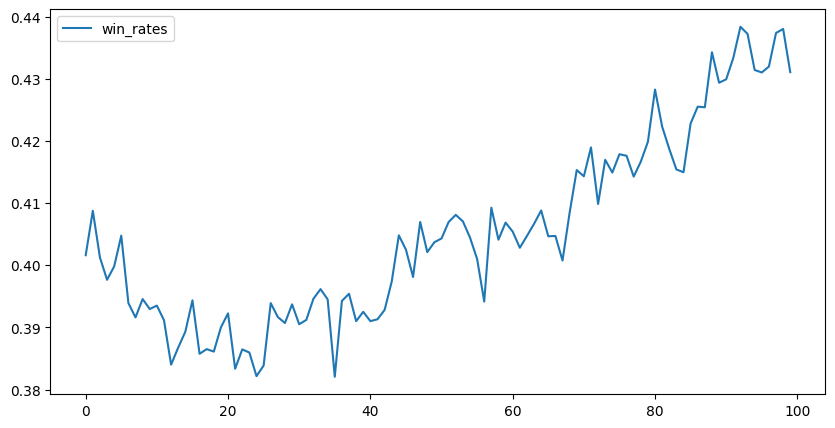

In [ ]:
plt.figure(figsize=(10,5))
plt.plot(win_rates, label='win_rates')
plt.legend()
plt.show()

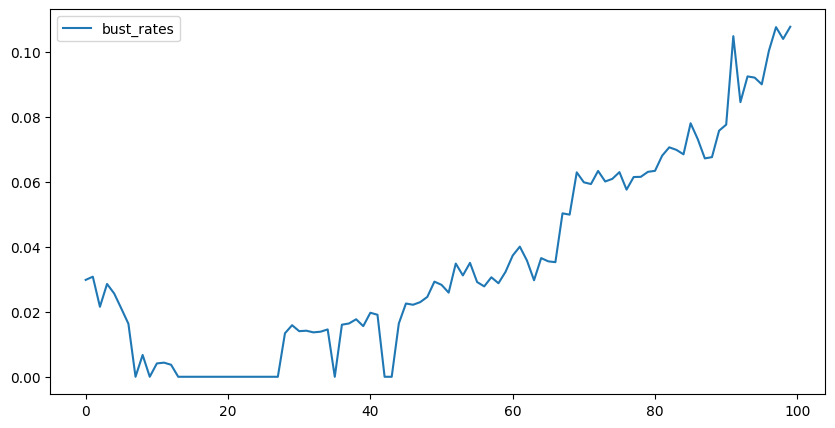

In [ ]:
plt.figure(figsize=(10,5))
plt.plot(bust_rate, label='bust_rates')
plt.legend()
plt.show()

In [ ]:
#make new policy network
new_policy_network = PolicyNetwork(45, env.action_space.n, 32, 32, 0.1)
#copy over parameters from best model
new_policy_network.load_state_dict(torch.load('/content/model_at_0.438.pt'))
agent = agent = EVOAgent(45, env.action_space.n, 0.1, 0.01, env)
agent.PolicyNetwork = new_policy_network

win_rates = []
player_bust_rates = []
dealer_win_rates = []

for _ in range(1000):
  win_rate, player_bust_rate, dealer_win_rate = agent.evaluate()
  win_rates.append(win_rate)
  player_bust_rates.append(player_bust_rate)
  dealer_win_rates.append(dealer_win_rate)

print(f"Win Rate: {np.mean(win_rates)}")
print(f"Player bust rate: {np.mean(player_bust_rates)}")
print(f"Dealer win rate: {np.mean(dealer_win_rates)}")



Win Rate: 0.4324658
Player bust rate: 0.08603334062166537
Dealer win rate: 0.9139666593783347


In [31]:
env = gym.make('Blackjack-v1', natural=False, sab=False)
#make new policy network
new_policy_network = PolicyNetwork(45, env.action_space.n, 32, 32, 0.1)
#copy over parameters from best model
new_policy_network.load_state_dict(torch.load('/content/drive/MyDrive/Reinforcement Learning Project/Evolution_Strategies_at_0.432.pt'))
agent = agent = EVOAgent(45, env.action_space.n, 0.1, 0.01, env)
agent.PolicyNetwork = new_policy_network


images = []
env.seed(93)
s = env.reset()
done = False

while not done:
    state = agent.one_hot_state(s)
    action = agent.PolicyNetwork.select_greedy_action(state)
    s, reward, done, _ = env.step(action)
    img = env.render(mode='rgb_array')
    images.append(img)

env.close()
write_apng('anim.png', images, delay=300)
Image(filename='anim.png')




-1.0
